Annual rainfall series: 1991-2025, n=35
Mean: 869.3 mm, std: 41.0 mm



C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


 year  annual_rainfall_mm  anomaly_mm   SPI      SPI_class  percentile                  decile_class kmeans_class  dry_votes(/3)  wet_votes(/3)  ROBUST_dry  ROBUST_wet
 1991          851.400024  -17.900000 -0.42    Near normal   37.099998                      Decile 4       normal              0              0       False       False
 1992          808.700012  -60.599998 -1.50   Severely dry    8.600000  Decile 1 (much below normal)          dry              3              0        True       False
 1993          792.700012  -76.599998 -1.91   Severely dry    2.900000  Decile 1 (much below normal)          dry              3              0        True       False
 1994          913.900024   44.599998  1.09 Moderately wet   82.900002       Decile 9 (above normal)          wet              0              3       False        True
 1995          857.900024  -11.300000 -0.26    Near normal   42.900002      Decile 5-6 (near normal)       normal              0              0       False     

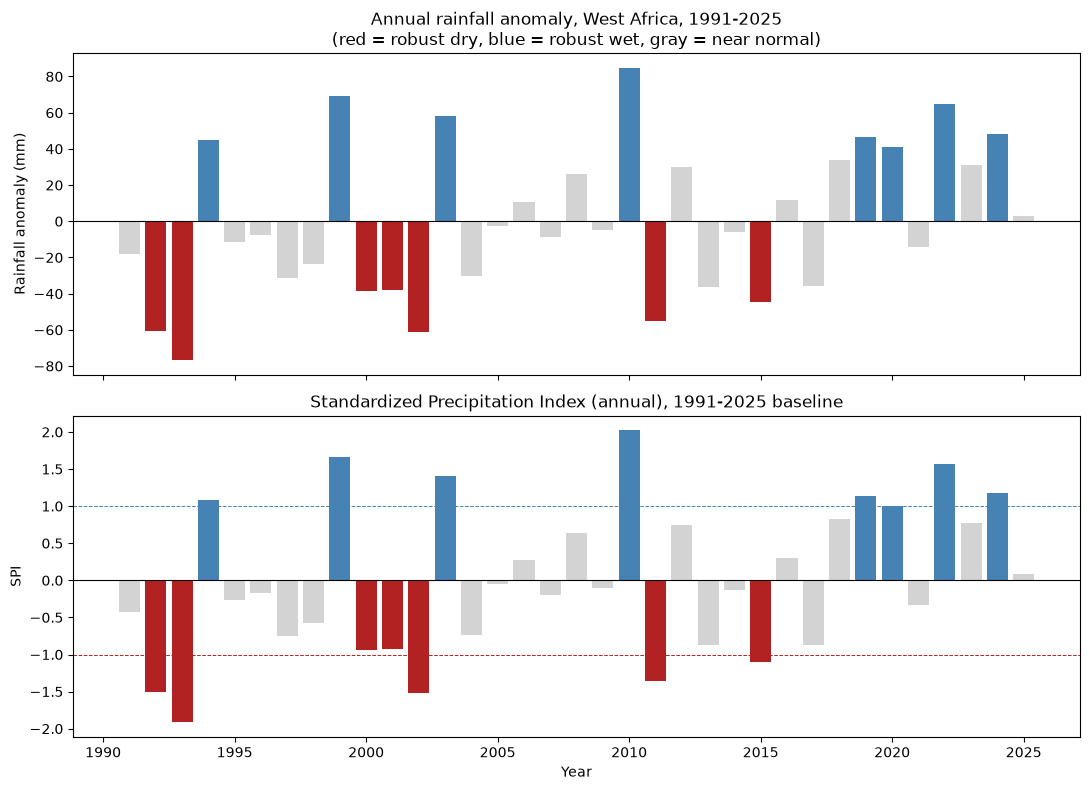

In [1]:
"""
Dry/wet year classification for West Africa, 1991-2025 (CRU TS precipitation).
Independent re-analysis -- does NOT reuse the 1981-2020 classification from the
earlier study.

Three independent classification methods are computed and cross-checked:
  1. Rainfall anomaly (raw departure from the 1991-2025 mean)
  2. Standardized Precipitation Index, 12-month / annual (McKee et al., 1993)
  3. Decile / percentile ranking (Gibbs and Maher, 1967 - the WMO/Australian
     Bureau of Meteorology drought-monitoring standard, and a genuinely
     different method since it makes no distributional assumption)
  4. K-means clustering (k=3) on the standardized annual series - a fully
     data-driven check that uses no fixed thresholds at all

A final "robust" dry/wet composite is built from years that agree across
at least 2 of the 3 threshold-based methods (SPI, decile, k-means).
"""

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

CRU_FILE = "cru_precip_1991_2025_westafrica.nc"


WA_LAT = (4.0, 20.0)   # degrees North
WA_LON = (-17.75, 15.75)  # degrees East

START_YEAR, END_YEAR = 1991, 2025

ds = xr.open_dataset(CRU_FILE)
pre = ds["pre"]  # mm/month

pre_wa = pre.sel(lat=slice(*WA_LAT), lon=slice(*WA_LON))

weights = np.cos(np.deg2rad(pre_wa.lat))
weights.name = "weights"

# spatial mean -> one value per month, skipping ocean/NaN cells
monthly_series = pre_wa.weighted(weights).mean(dim=("lat", "lon"), skipna=True)

# aggregate to annual totals (sum of the 12 monthly means)
annual = monthly_series.groupby("time.year").sum(skipna=True)
annual = annual.sel(year=slice(START_YEAR, END_YEAR))

years = annual.year.values
values = annual.values  # annual total rainfall, mm

print(f"Annual rainfall series: {years.min()}-{years.max()}, n={len(years)}")
print(f"Mean: {values.mean():.1f} mm, std: {values.std():.1f} mm")
print()


# Method 1 - rainfall anomaly (raw departure from the period mean)

clim_mean = values.mean()
anomaly = values - clim_mean


# Method 2 - SPI (McKee et al., 1993), gamma-fitted, 1991-2025 baseline

shape, loc, scale = stats.gamma.fit(values, floc=0)  # floc=0: gamma undefined for <=0
cdf_vals = stats.gamma.cdf(values, shape, loc=loc, scale=scale)
cdf_vals = np.clip(cdf_vals, 1e-6, 1 - 1e-6)
spi = stats.norm.ppf(cdf_vals)

def spi_category(s):
    if s >= 2.0:   return "Extremely wet"
    if s >= 1.5:   return "Very wet"
    if s >= 1.0:   return "Moderately wet"
    if s > -1.0:   return "Near normal"
    if s > -1.5:   return "Moderately dry"
    if s > -2.0:   return "Severely dry"
    return "Extremely dry"

spi_class = [spi_category(s) for s in spi]
spi_is_dry = np.array(["dry" in c.lower() for c in spi_class])
spi_is_wet = np.array(["wet" in c.lower() for c in spi_class])


# Method 3 - Decile ranking (Gibbs and Maher, 1967)

percentile_rank = stats.rankdata(values) / len(values) * 100  # 0-100

def decile_category(p):
    if p <= 10:  return "Decile 1 (much below normal)"
    if p <= 20:  return "Decile 2 (below normal)"
    if p <= 30:  return "Decile 3"
    if p <= 40:  return "Decile 4"
    if p <= 60:  return "Decile 5-6 (near normal)"
    if p <= 70:  return "Decile 7"
    if p <= 80:  return "Decile 8"
    if p <= 90:  return "Decile 9 (above normal)"
    return "Decile 10 (much above normal)"

decile_class = [decile_category(p) for p in percentile_rank]
decile_is_dry = percentile_rank <= 20   # bottom 2 deciles
decile_is_wet = percentile_rank >= 80   # top 2 deciles


# Method 4 - K-means clustering (k=3), fully data-driven

z = (values - values.mean()) / values.std()
km = KMeans(n_clusters=3, n_init=10, random_state=0)
labels = km.fit_predict(z.reshape(-1, 1))

centroid_order = np.argsort(km.cluster_centers_.flatten())
label_map = {centroid_order[0]: "dry", centroid_order[1]: "normal", centroid_order[2]: "wet"}
kmeans_class = np.array([label_map[l] for l in labels])
kmeans_is_dry = kmeans_class == "dry"
kmeans_is_wet = kmeans_class == "wet"


# Cross-method comparison and robust composite
n_dry_votes = spi_is_dry.astype(int) + decile_is_dry.astype(int) + kmeans_is_dry.astype(int)
n_wet_votes = spi_is_wet.astype(int) + decile_is_wet.astype(int) + kmeans_is_wet.astype(int)

robust_dry = n_dry_votes >= 2
robust_wet = n_wet_votes >= 2

summary = pd.DataFrame({
    "year": years,
    "annual_rainfall_mm": np.round(values, 1),
    "anomaly_mm": np.round(anomaly, 1),
    "SPI": np.round(spi, 2),
    "SPI_class": spi_class,
    "percentile": np.round(percentile_rank, 1),
    "decile_class": decile_class,
    "kmeans_class": kmeans_class,
    "dry_votes(/3)": n_dry_votes,
    "wet_votes(/3)": n_wet_votes,
    "ROBUST_dry": robust_dry,
    "ROBUST_wet": robust_wet,
})

pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 100)
print(summary.to_string(index=False))
print()

robust_dry_years = summary.loc[summary.ROBUST_dry, "year"].tolist()
robust_wet_years = summary.loc[summary.ROBUST_wet, "year"].tolist()
print("ROBUST DRY years (>=2/3 methods agree):", robust_dry_years)
print("ROBUST WET years (>=2/3 methods agree):", robust_wet_years)

summary.to_csv("dry_wet_classification_1991_2025.csv", index=False)
print("\nSaved: dry_wet_classification_1991_2025.csv")


# Plots

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

colors = np.where(robust_dry, "firebrick", np.where(robust_wet, "steelblue", "lightgray"))

axes[0].bar(years, anomaly, color=colors)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Rainfall anomaly (mm)")
axes[0].set_title("Annual rainfall anomaly, West Africa, 1991-2025\n"
                   "(red = robust dry, blue = robust wet, gray = near normal)")

axes[1].bar(years, spi, color=colors)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].axhline(-1, color="firebrick", linestyle="--", linewidth=0.7)
axes[1].axhline(1, color="steelblue", linestyle="--", linewidth=0.7)
axes[1].set_ylabel("SPI")
axes[1].set_xlabel("Year")
axes[1].set_title("Standardized Precipitation Index (annual), 1991-2025 baseline")

plt.tight_layout()
plt.savefig("dry_wet_classification_1991_2025.png", dpi=200)
print("Saved: dry_wet_classification_1991_2025.png")

C:\Users\HP\anaconda3\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Saved: composite_SST_dry_wet.png
Saved: composite_MSLP_wind_dry_wet.png
Saved: composite_humidity_dry_wet.png
Saved: composite_differences_JJA.png

All composites built successfully, with boundaries.


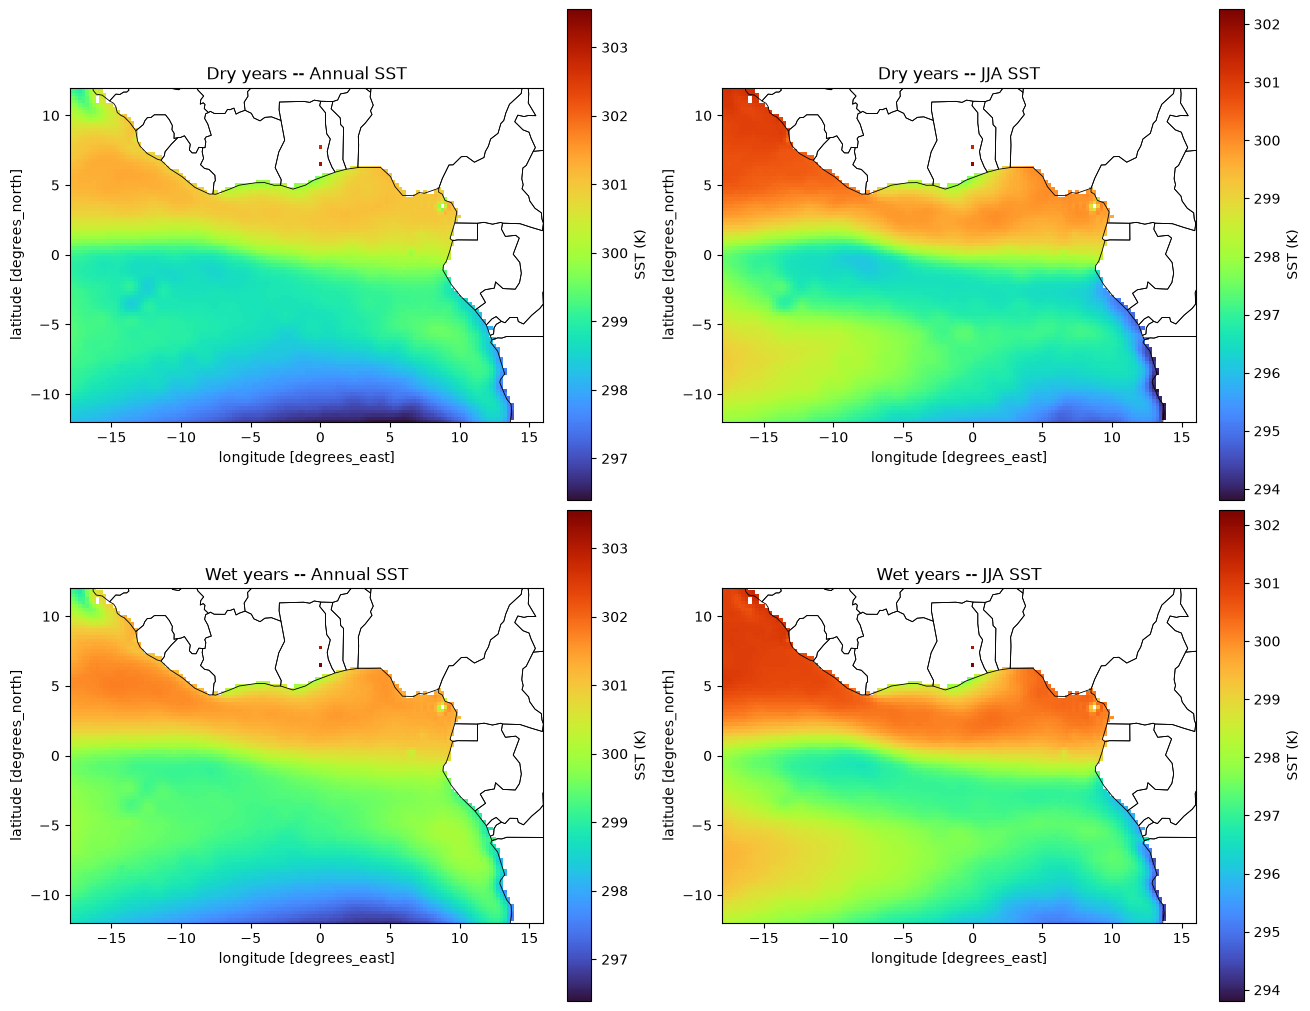

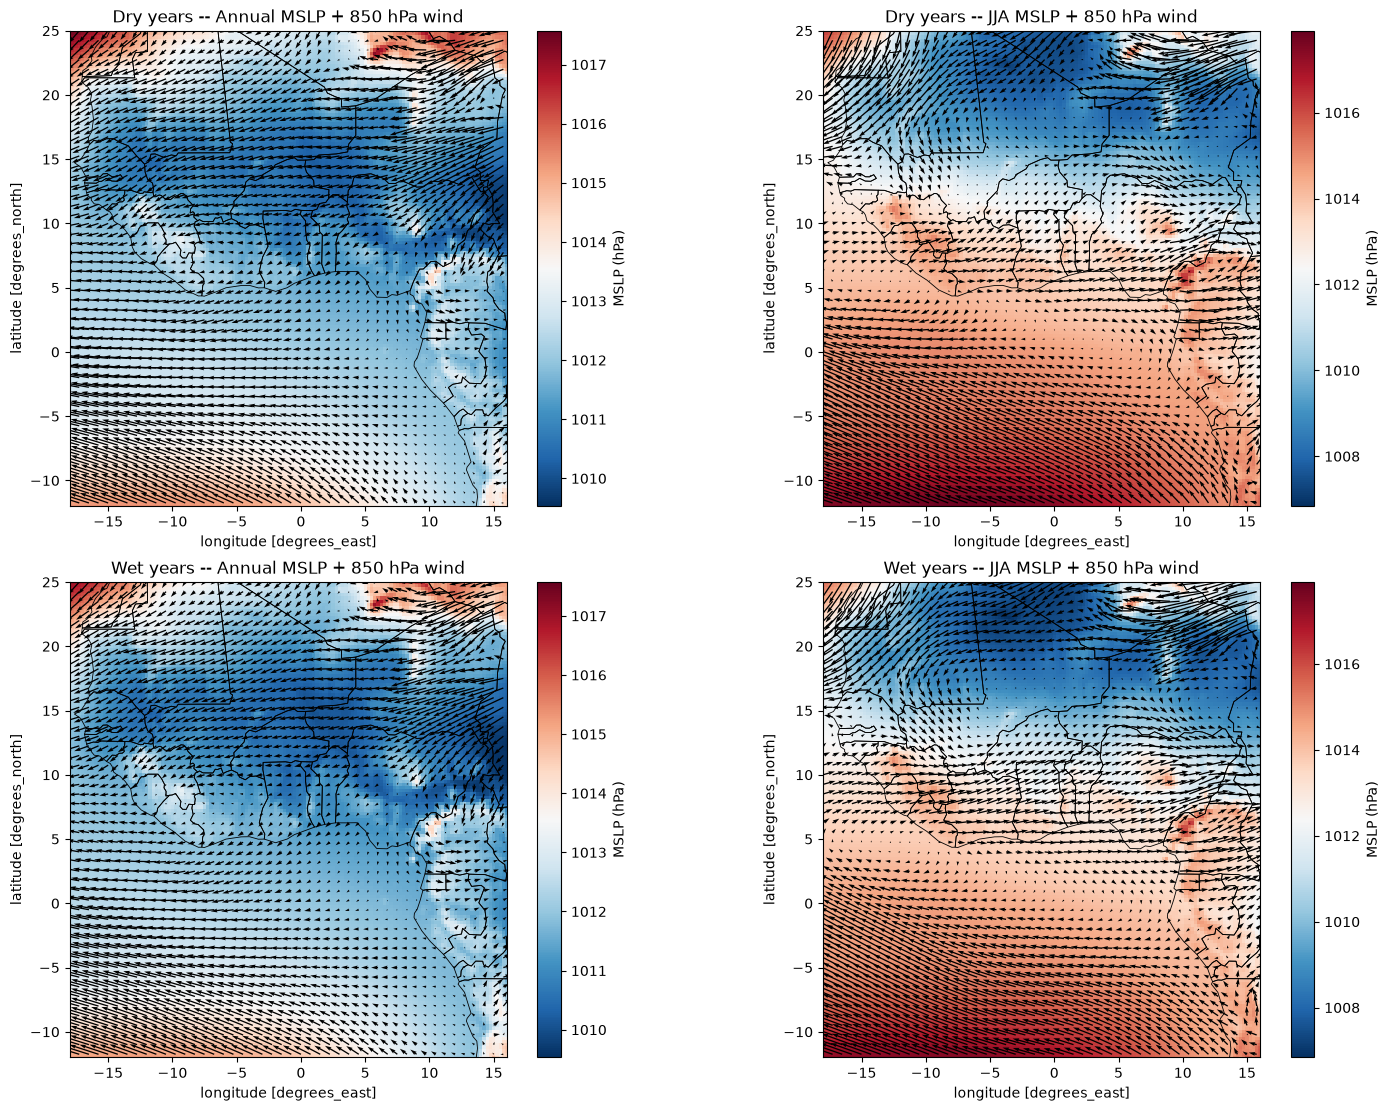

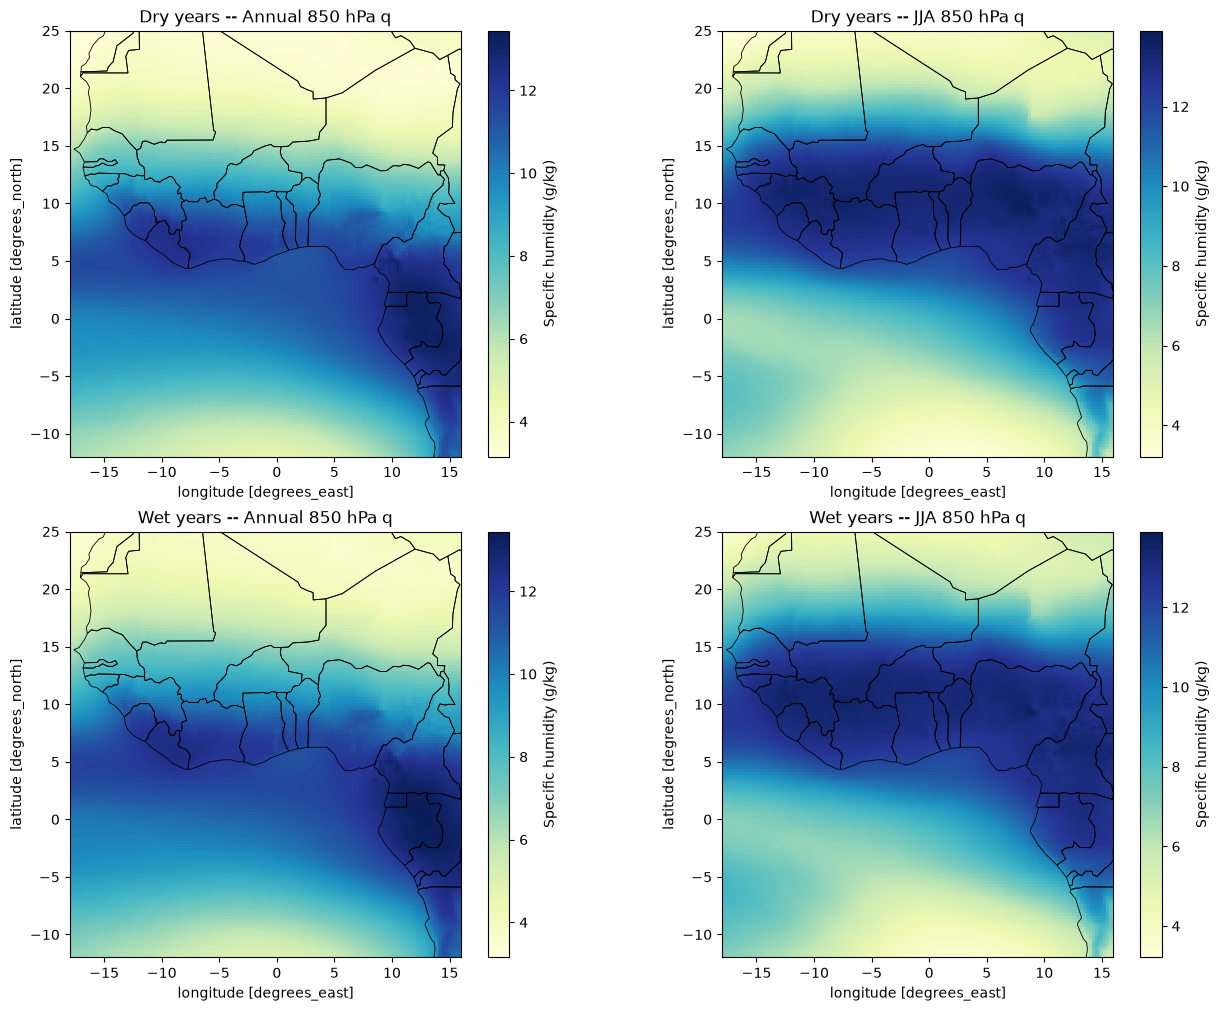

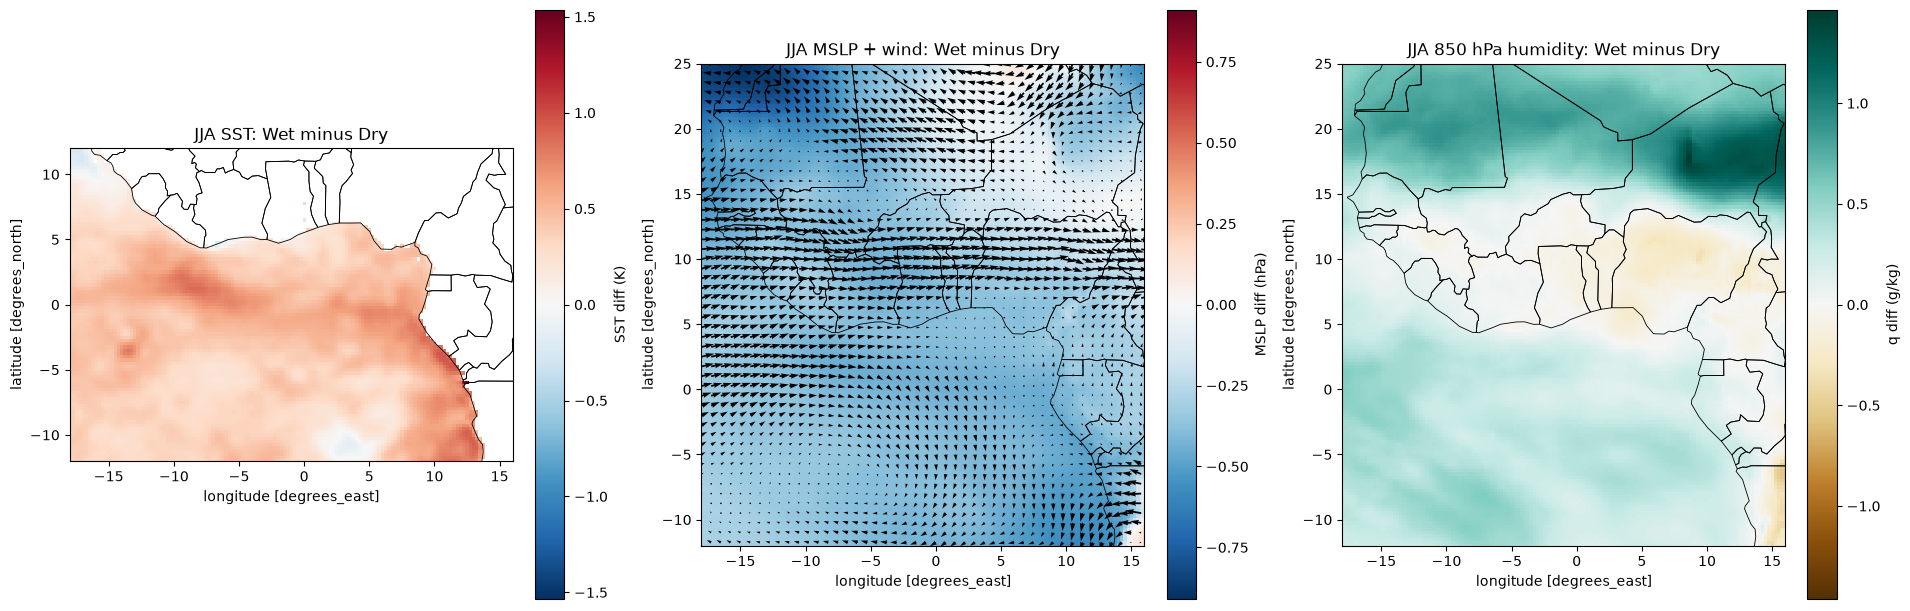

In [1]:
"""
Composite maps of SST, MSLP, and 850 hPa wind/humidity for the dry-year and
wet-year groups, with country/coastline boundaries overlaid.

Dry years (n=7): 1992, 1993, 2000, 2001, 2002, 2011, 2015
Wet years (n=8): 1994, 1999, 2003, 2010, 2019, 2020, 2022, 2024
"""

import os
import urllib.request
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import geopandas as gpd

DRY_YEARS = [1992, 1993, 2000, 2001, 2002, 2011, 2015]
WET_YEARS = [1994, 1999, 2003, 2010, 2019, 2020, 2022, 2024]


# Get country boundaries

GEOJSON_PATH = "countries.geojson"
GEOJSON_URL = ("https://raw.githubusercontent.com/nvkelso/"
               "natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson")

if not os.path.exists(GEOJSON_PATH):
    print("Downloading country boundaries (one-time)...")
    urllib.request.urlretrieve(GEOJSON_URL, GEOJSON_PATH)

world = gpd.read_file(GEOJSON_PATH)

def add_boundaries(ax, extent):
    """Draw country borders on a plain matplotlib (non-cartopy) axis."""
    world.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")


# Load data

sst = xr.open_dataset("SST.nc").rename({"valid_time": "time"})["sst"]
mslp = xr.open_dataset("MSLP.nc").rename({"valid_time": "time"})["msl"] / 100.0  # Pa -> hPa
wsh = xr.open_dataset("Wind_SH.nc").rename({"valid_time": "time"}).squeeze("pressure_level", drop=True)
u = wsh["u"]
v = wsh["v"]
q = wsh["q"] * 1000.0  # kg/kg -> g/kg

SST_EXTENT = [float(sst.longitude.min()), float(sst.longitude.max()),
              float(sst.latitude.min()), float(sst.latitude.max())]
WA_EXTENT = [float(mslp.longitude.min()), float(mslp.longitude.max()),
             float(mslp.latitude.min()), float(mslp.latitude.max())]

def season_sel(da, months):
    return da.sel(time=da["time"].dt.month.isin(months))

def year_composite(da, years, months=None):
    d = da if months is None else season_sel(da, months)
    d = d.sel(time=d["time"].dt.year.isin(years))
    return d.mean(dim="time")

SEASONS = {"Annual": list(range(1, 13)), "JJA": [6, 7, 8]}


# SST composites, dry vs wet, Annual and JJA
fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
for col, (sname, months) in enumerate(SEASONS.items()):
    dry_sst = year_composite(sst, DRY_YEARS, months)
    wet_sst = year_composite(sst, WET_YEARS, months)
    vmin = min(float(dry_sst.min()), float(wet_sst.min()))
    vmax = max(float(dry_sst.max()), float(wet_sst.max()))
    for row, (label, field) in enumerate([("Dry", dry_sst), ("Wet", wet_sst)]):
        ax = axes[row, col]
        field.plot(ax=ax, vmin=vmin, vmax=vmax, cmap="turbo", add_colorbar=True,
                   cbar_kwargs={"label": "SST (K)"})
        add_boundaries(ax, SST_EXTENT)
        ax.set_title(f"{label} years -- {sname} SST")
plt.savefig("composite_SST_dry_wet.png", dpi=200)
print("Saved: composite_SST_dry_wet.png")

# MSLP + 850 hPa wind, dry vs wet, Annual and JJA

fig, axes = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)
for col, (sname, months) in enumerate(SEASONS.items()):
    dry_mslp = year_composite(mslp, DRY_YEARS, months)
    wet_mslp = year_composite(mslp, WET_YEARS, months)
    dry_u = year_composite(u, DRY_YEARS, months); dry_v = year_composite(v, DRY_YEARS, months)
    wet_u = year_composite(u, WET_YEARS, months); wet_v = year_composite(v, WET_YEARS, months)
    vmin = min(float(dry_mslp.min()), float(wet_mslp.min()))
    vmax = max(float(dry_mslp.max()), float(wet_mslp.max()))
    for row, (label, mfield, ufield, vfield) in enumerate([
        ("Dry", dry_mslp, dry_u, dry_v), ("Wet", wet_mslp, wet_u, wet_v)
    ]):
        ax = axes[row, col]
        mfield.plot(ax=ax, vmin=vmin, vmax=vmax, cmap="RdBu_r", add_colorbar=True,
                    cbar_kwargs={"label": "MSLP (hPa)"})
        skip = 3
        ax.quiver(ufield.longitude[::skip], ufield.latitude[::skip],
                  ufield.values[::skip, ::skip], vfield.values[::skip, ::skip],
                  scale=80, width=0.003)
        add_boundaries(ax, WA_EXTENT)
        ax.set_title(f"{label} years -- {sname} MSLP + 850 hPa wind")
plt.savefig("composite_MSLP_wind_dry_wet.png", dpi=200)
print("Saved: composite_MSLP_wind_dry_wet.png")


# 850 hPa specific humidity, dry vs wet, Annual and JJA

fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
for col, (sname, months) in enumerate(SEASONS.items()):
    dry_q = year_composite(q, DRY_YEARS, months)
    wet_q = year_composite(q, WET_YEARS, months)
    vmin = min(float(dry_q.min()), float(wet_q.min()))
    vmax = max(float(dry_q.max()), float(wet_q.max()))
    for row, (label, field) in enumerate([("Dry", dry_q), ("Wet", wet_q)]):
        ax = axes[row, col]
        field.plot(ax=ax, vmin=vmin, vmax=vmax, cmap="YlGnBu", add_colorbar=True,
                   cbar_kwargs={"label": "Specific humidity (g/kg)"})
        add_boundaries(ax, WA_EXTENT)
        ax.set_title(f"{label} years -- {sname} 850 hPa q")
plt.savefig("composite_humidity_dry_wet.png", dpi=200)
print("Saved: composite_humidity_dry_wet.png")

# Difference maps (wet minus dry), JJA -- the key diagnostic figure

fig, axes = plt.subplots(1, 3, figsize=(19, 6), constrained_layout=True)

sst_diff = year_composite(sst, WET_YEARS, SEASONS["JJA"]) - year_composite(sst, DRY_YEARS, SEASONS["JJA"])
sst_diff.plot(ax=axes[0], cmap="RdBu_r", center=0, cbar_kwargs={"label": "SST diff (K)"})
add_boundaries(axes[0], SST_EXTENT)
axes[0].set_title("JJA SST: Wet minus Dry")

mslp_diff = year_composite(mslp, WET_YEARS, SEASONS["JJA"]) - year_composite(mslp, DRY_YEARS, SEASONS["JJA"])
mslp_diff.plot(ax=axes[1], cmap="RdBu_r", center=0, cbar_kwargs={"label": "MSLP diff (hPa)"})
u_diff = year_composite(u, WET_YEARS, SEASONS["JJA"]) - year_composite(u, DRY_YEARS, SEASONS["JJA"])
v_diff = year_composite(v, WET_YEARS, SEASONS["JJA"]) - year_composite(v, DRY_YEARS, SEASONS["JJA"])
skip = 3
axes[1].quiver(u_diff.longitude[::skip], u_diff.latitude[::skip],
              u_diff.values[::skip, ::skip], v_diff.values[::skip, ::skip], scale=40, width=0.004)
add_boundaries(axes[1], WA_EXTENT)
axes[1].set_title("JJA MSLP + wind: Wet minus Dry")

q_diff = year_composite(q, WET_YEARS, SEASONS["JJA"]) - year_composite(q, DRY_YEARS, SEASONS["JJA"])
q_diff.plot(ax=axes[2], cmap="BrBG", center=0, cbar_kwargs={"label": "q diff (g/kg)"})
add_boundaries(axes[2], WA_EXTENT)
axes[2].set_title("JJA 850 hPa humidity: Wet minus Dry")

plt.savefig("composite_differences_JJA.png", dpi=200)
print("Saved: composite_differences_JJA.png")

print("\nAll composites built successfully, with boundaries.")

C:\Users\HP\AppData\Local\Temp\ipykernel_5940\3042827299.py:83: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  tstat, pvalue = stats.ttest_ind(sample_wet, sample_dry, axis=0,


SST: 22.5% of grid cells significant at p < 0.05
MSLP: 11.7% of grid cells significant at p < 0.05
q (850 hPa): 24.9% of grid cells significant at p < 0.05

Saved: composite_differences_JJA_significance.png


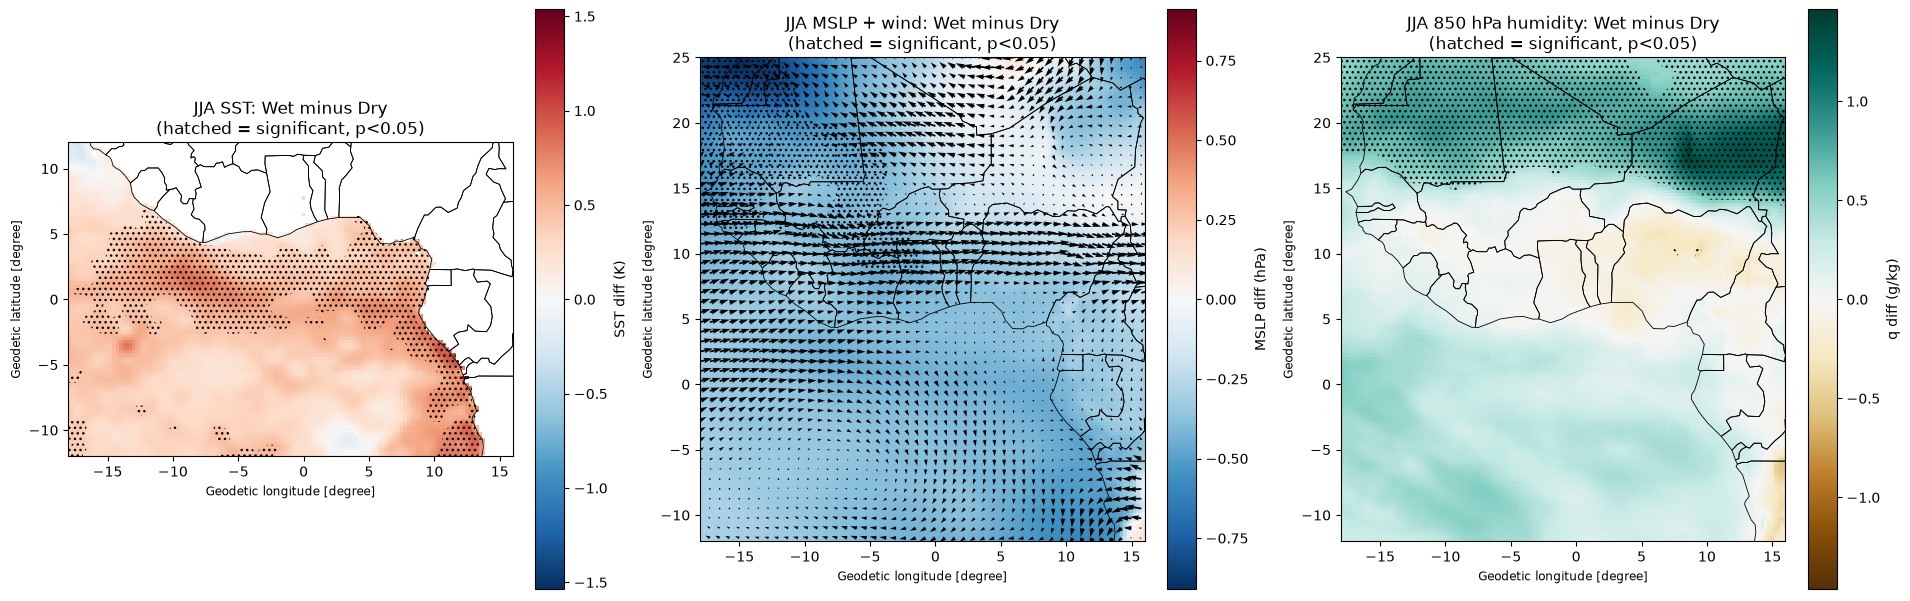

In [2]:
"""
Statistical significance testing on the wet-minus-dry JJA difference
composites (SST, MSLP, 850 hPa wind, 850 hPa specific humidity).

For each grid cell, a Welch's two-sample t-test (unequal variance, since
n_dry=7 != n_wet=8) is run between the 7 dry-year JJA means and the 8
wet-year JJA means. Grid cells where p < 0.05 are hatched on the
difference maps - this is the standard way to show that a spatial
difference pattern is not just noise from a small sample.
"""

import os
import urllib.request
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats
import geopandas as gpd

DRY_YEARS = [1992, 1993, 2000, 2001, 2002, 2011, 2015]
WET_YEARS = [1994, 1999, 2003, 2010, 2019, 2020, 2022, 2024]
JJA_MONTHS = [6, 7, 8]
ALPHA = 0.05  # significance level

# Country boundaries

GEOJSON_PATH = "countries.geojson"
GEOJSON_URL = ("https://raw.githubusercontent.com/nvkelso/"
               "natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson")

if not os.path.exists(GEOJSON_PATH):
    print("Downloading country boundaries (one-time)...")
    urllib.request.urlretrieve(GEOJSON_URL, GEOJSON_PATH)

world = gpd.read_file(GEOJSON_PATH)

def add_boundaries(ax, extent):
    world.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")


# Load data

sst = xr.open_dataset("SST.nc").rename({"valid_time": "time"})["sst"]
mslp = xr.open_dataset("MSLP.nc").rename({"valid_time": "time"})["msl"] / 100.0  # Pa -> hPa
wsh = xr.open_dataset("Wind_SH.nc").rename({"valid_time": "time"}).squeeze("pressure_level", drop=True)
u = wsh["u"]
v = wsh["v"]
q = wsh["q"] * 1000.0  # kg/kg -> g/kg

SST_EXTENT = [float(sst.longitude.min()), float(sst.longitude.max()),
              float(sst.latitude.min()), float(sst.latitude.max())]
WA_EXTENT = [float(mslp.longitude.min()), float(mslp.longitude.max()),
             float(mslp.latitude.min()), float(mslp.latitude.max())]


# Build per-year JJA seasonal-mean samples

def per_year_jja_samples(da, years):
    """Returns a DataArray stacked on a new 'year' dimension, each entry
    being that year's JJA mean -- i.e. shape (n_years, lat, lon)."""
    jja = da.sel(time=da["time"].dt.month.isin(JJA_MONTHS))
    yearly = jja.groupby("time.year").mean("time")
    return yearly.sel(year=years)

def welch_ttest_grid(sample_dry, sample_wet):
    """Vectorized Welch's t-test at every grid cell.
    sample_dry, sample_wet: numpy arrays shaped (n_years, lat, lon).
    Returns: tstat, pvalue arrays shaped (lat, lon)."""
    tstat, pvalue = stats.ttest_ind(sample_wet, sample_dry, axis=0,
                                     equal_var=False, nan_policy="omit")
    return tstat, pvalue

def plot_diff_with_significance(ax, lon, lat, diff, pvalue, cmap, label, quiver=None):
    im = ax.pcolormesh(lon, lat, diff, cmap=cmap,
                        vmin=-np.nanmax(np.abs(diff)), vmax=np.nanmax(np.abs(diff)))
    plt.colorbar(im, ax=ax, label=label)

    # hatch the cells that ARE significant so the eye is drawn to where
    # the signal is robust, not just where the color looks strong
    sig_mask = (pvalue < ALPHA).astype(float)
    ax.contourf(lon, lat, sig_mask, levels=[0.5, 1.5], colors="none",
                hatches=["..."], extend="neither")

    if quiver is not None:
        u_diff, v_diff, skip = quiver
        ax.quiver(lon[::skip], lat[::skip],
                  u_diff[::skip, ::skip], v_diff[::skip, ::skip],
                  scale=40, width=0.004)


# SST significance

sst_dry = per_year_jja_samples(sst, DRY_YEARS)
sst_wet = per_year_jja_samples(sst, WET_YEARS)
sst_diff = sst_wet.mean("year") - sst_dry.mean("year")
_, sst_p = welch_ttest_grid(sst_dry.values, sst_wet.values)


# MSLP + wind significance

mslp_dry = per_year_jja_samples(mslp, DRY_YEARS)
mslp_wet = per_year_jja_samples(mslp, WET_YEARS)
mslp_diff = mslp_wet.mean("year") - mslp_dry.mean("year")
_, mslp_p = welch_ttest_grid(mslp_dry.values, mslp_wet.values)

u_dry = per_year_jja_samples(u, DRY_YEARS); u_wet = per_year_jja_samples(u, WET_YEARS)
v_dry = per_year_jja_samples(v, DRY_YEARS); v_wet = per_year_jja_samples(v, WET_YEARS)
u_diff = u_wet.mean("year") - u_dry.mean("year")
v_diff = v_wet.mean("year") - v_dry.mean("year")

# Specific humidity significance

q_dry = per_year_jja_samples(q, DRY_YEARS)
q_wet = per_year_jja_samples(q, WET_YEARS)
q_diff = q_wet.mean("year") - q_dry.mean("year")
_, q_p = welch_ttest_grid(q_dry.values, q_wet.values)

# Report the fraction of the domain that is significant 
for name, p in [("SST", sst_p), ("MSLP", mslp_p), ("q (850 hPa)", q_p)]:
    frac_sig = np.nanmean(p < ALPHA) * 100
    print(f"{name}: {frac_sig:.1f}% of grid cells significant at p < {ALPHA}")


# Plot: three panels, hatched where p < 0.05

fig, axes = plt.subplots(1, 3, figsize=(19, 6), constrained_layout=True)

plot_diff_with_significance(axes[0], sst_diff.longitude, sst_diff.latitude,
                             sst_diff.values, sst_p, "RdBu_r", "SST diff (K)")
add_boundaries(axes[0], SST_EXTENT)
axes[0].set_title(f"JJA SST: Wet minus Dry\n(hatched = significant, p<{ALPHA})")

plot_diff_with_significance(axes[1], mslp_diff.longitude, mslp_diff.latitude,
                             mslp_diff.values, mslp_p, "RdBu_r", "MSLP diff (hPa)",
                             quiver=(u_diff.values, v_diff.values, 3))
add_boundaries(axes[1], WA_EXTENT)
axes[1].set_title(f"JJA MSLP + wind: Wet minus Dry\n(hatched = significant, p<{ALPHA})")

plot_diff_with_significance(axes[2], q_diff.longitude, q_diff.latitude,
                             q_diff.values, q_p, "BrBG", "q diff (g/kg)")
add_boundaries(axes[2], WA_EXTENT)
axes[2].set_title(f"JJA 850 hPa humidity: Wet minus Dry\n(hatched = significant, p<{ALPHA})")

plt.savefig("composite_differences_JJA_significance.png", dpi=200)
print("\nSaved: composite_differences_JJA_significance.png")

Aligned monthly series: 1991-01-01 to 2025-12-01, n=420

--- Monthly regression (SST vs precipitation) ---
slope=-31.4089, intercept=9480.0569, R=-0.7320, p=0.000000, stderr=1.4299, n=420

--- Annual regression (SST vs precipitation) ---
slope=77.3680, intercept=-22304.0484, R=0.5553, p=0.000535, stderr=20.1696, n=35

--- Two-month lag regression (SST(t) vs precipitation(t+2)) ---
slope=4.8250, intercept=-1372.4456, R=0.1127, R2=0.0127, p=0.021165, stderr=2.0853, n=418

Saved: sst_precip_monthly_1991_2025.csv, sst_precip_annual_1991_2025.csv, regression_summary_1991_2025.csv
Saved: regression_SST_precip_1991_2025.png


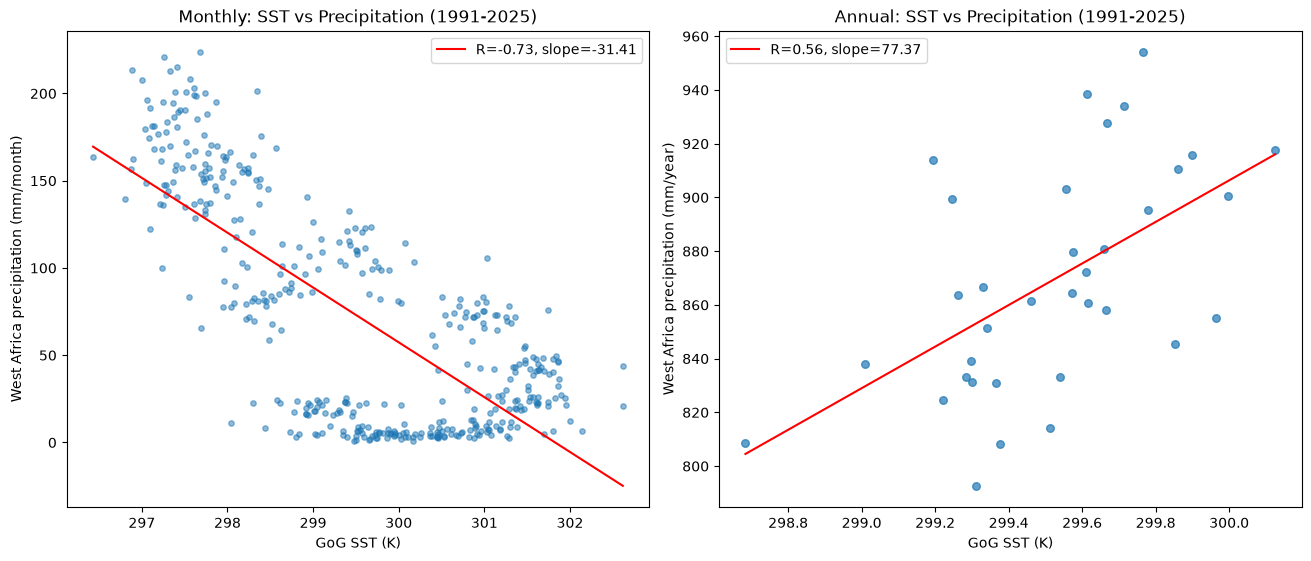

In [1]:
"""
SST-precipitation regression analysis, 1991-2025 - fully independent
re-derivation (does not reuse any 1981-2020 numbers from the earlier study).

Computes:
  1. Monthly regression: GoG SST vs West Africa precipitation
  2. Annual regression: GoG SST vs West Africa precipitation
  3. Two-month lag regression: GoG SST (month t) vs precipitation (month t+2)
"""

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt

SST_FILE = "SST.nc"
CRU_FILE = "cru_precip_1991_2025_westafrica.nc"

# Same core West Africa land box used in the dry/wet classification step,
# for consistency across the whole analysis
WA_LAT = (4.0, 20.0)
WA_LON = (-17.75, 15.75)

START_YEAR, END_YEAR = 1991, 2025


# Build the regional-mean SST series (GoG box, area-weighted)

sst = xr.open_dataset(SST_FILE).rename({"valid_time": "time"})["sst"]
weights_sst = np.cos(np.deg2rad(sst.latitude))
sst_series = sst.weighted(weights_sst).mean(dim=("latitude", "longitude"), skipna=True)
sst_monthly = sst_series.to_pandas()
sst_monthly.index = sst_monthly.index.to_period("M").to_timestamp()


# Build the regional-mean precipitation series 
pre = xr.open_dataset(CRU_FILE)["pre"]
pre_wa = pre.sel(lat=slice(*WA_LAT), lon=slice(*WA_LON))
weights_pre = np.cos(np.deg2rad(pre_wa.lat))
pre_series = pre_wa.weighted(weights_pre).mean(dim=("lat", "lon"), skipna=True)
pre_monthly = pre_series.to_pandas()
pre_monthly.index = pre_monthly.index.to_period("M").to_timestamp()


# Align the two series on a common monthly index, 1991-2025

df = pd.DataFrame({"SST": sst_monthly, "PRE": pre_monthly}).dropna()
df = df.loc[f"{START_YEAR}-01":f"{END_YEAR}-12"]
print(f"Aligned monthly series: {df.index.min().date()} to {df.index.max().date()}, n={len(df)}")
assert len(df) == (END_YEAR - START_YEAR + 1) * 12, "Missing months after alignment - check inputs"


# Monthly regression: SST vs precipitation

res_monthly = stats.linregress(df["SST"], df["PRE"])
print("\n--- Monthly regression (SST vs precipitation) ---")
print(f"slope={res_monthly.slope:.4f}, intercept={res_monthly.intercept:.4f}, "
      f"R={res_monthly.rvalue:.4f}, p={res_monthly.pvalue:.6f}, "
      f"stderr={res_monthly.stderr:.4f}, n={len(df)}")


# Annual regression: SST vs precipitation

annual = df.groupby(df.index.year).agg({"SST": "mean", "PRE": "sum"})
res_annual = stats.linregress(annual["SST"], annual["PRE"])
print("\n--- Annual regression (SST vs precipitation) ---")
print(f"slope={res_annual.slope:.4f}, intercept={res_annual.intercept:.4f}, "
      f"R={res_annual.rvalue:.4f}, p={res_annual.pvalue:.6f}, "
      f"stderr={res_annual.stderr:.4f}, n={len(annual)}")


# Two-month lag regression: SST(t) vs precipitation(t+2)

df_lag = df.copy()
df_lag["PRE_lag2"] = df_lag["PRE"].shift(-2)  # precipitation 2 months AFTER this SST value
df_lag = df_lag.dropna()

res_lag = stats.linregress(df_lag["SST"], df_lag["PRE_lag2"])
r2_lag = res_lag.rvalue ** 2
print("\n--- Two-month lag regression (SST(t) vs precipitation(t+2)) ---")
print(f"slope={res_lag.slope:.4f}, intercept={res_lag.intercept:.4f}, "
      f"R={res_lag.rvalue:.4f}, R2={r2_lag:.4f}, p={res_lag.pvalue:.6f}, "
      f"stderr={res_lag.stderr:.4f}, n={len(df_lag)}")


# Save the aligned series and a summary table

df.to_csv("sst_precip_monthly_1991_2025.csv")
annual.to_csv("sst_precip_annual_1991_2025.csv")

summary = pd.DataFrame([
    {"regression": "Monthly", "slope": res_monthly.slope, "R": res_monthly.rvalue,
     "p_value": res_monthly.pvalue, "stderr": res_monthly.stderr, "n": len(df)},
    {"regression": "Annual", "slope": res_annual.slope, "R": res_annual.rvalue,
     "p_value": res_annual.pvalue, "stderr": res_annual.stderr, "n": len(annual)},
    {"regression": "2-month lag", "slope": res_lag.slope, "R": res_lag.rvalue,
     "R2": r2_lag, "p_value": res_lag.pvalue, "stderr": res_lag.stderr, "n": len(df_lag)},
])
summary.to_csv("regression_summary_1991_2025.csv", index=False)
print("\nSaved: sst_precip_monthly_1991_2025.csv, sst_precip_annual_1991_2025.csv, "
      "regression_summary_1991_2025.csv")


# Plots - monthly and annual scatter with fitted line

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)

axes[0].scatter(df["SST"], df["PRE"], alpha=0.5, s=15)
xfit = np.linspace(df["SST"].min(), df["SST"].max(), 100)
axes[0].plot(xfit, res_monthly.slope * xfit + res_monthly.intercept, color="red",
             label=f"R={res_monthly.rvalue:.2f}, slope={res_monthly.slope:.2f}")
axes[0].set_xlabel("GoG SST (K)"); axes[0].set_ylabel("West Africa precipitation (mm/month)")
axes[0].set_title("Monthly: SST vs Precipitation (1991-2025)")
axes[0].legend()

axes[1].scatter(annual["SST"], annual["PRE"], alpha=0.7, s=30)
xfit2 = np.linspace(annual["SST"].min(), annual["SST"].max(), 100)
axes[1].plot(xfit2, res_annual.slope * xfit2 + res_annual.intercept, color="red",
             label=f"R={res_annual.rvalue:.2f}, slope={res_annual.slope:.2f}")
axes[1].set_xlabel("GoG SST (K)"); axes[1].set_ylabel("West Africa precipitation (mm/year)")
axes[1].set_title("Annual: SST vs Precipitation (1991-2025)")
axes[1].legend()

plt.savefig("regression_SST_precip_1991_2025.png", dpi=200)
print("Saved: regression_SST_precip_1991_2025.png")

 lag_months        R  p_value   n
         -3 0.172256 0.000410 417
         -2 0.175111 0.000322 418
         -1 0.147476 0.002476 419
          0 0.099847 0.040829 420
          1 0.104059 0.033217 419
          2 0.143008 0.003388 418
          3 0.135272 0.005662 417
          4 0.112567 0.021658 416
          5 0.149610 0.002244 415
          6 0.146559 0.002797 414
          7 0.157523 0.001320 413
          8 0.162866 0.000907 412
          9 0.183837 0.000179 411
         10 0.199122 0.000049 410
         11 0.180615 0.000241 409
         12 0.155600 0.001619 408

Significant lags (p<0.05): [-3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Strongest correlation at lag=10 months: R=0.199, p=0.0000
Saved: lag_scan.png, lag_scan_results.csv


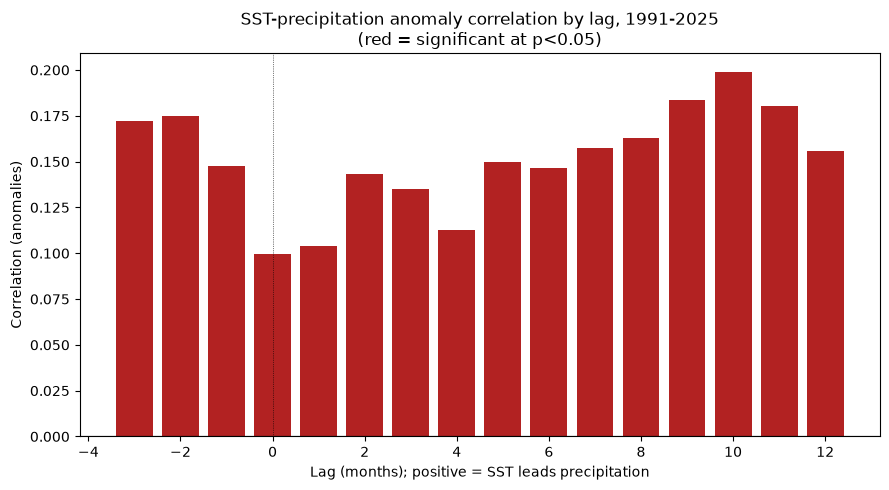

In [3]:
"""
Lag-correlation scan: at what lag (in months) does a GoG SST anomaly
best/most significantly relate to a West Africa precipitation anomaly?

Works on deseasonalized ANOMALIES (each series minus its own 1991-2025
monthly climatology), so the shared seasonal cycle doesn't manufacture a
spurious "significant" result at every lag.
"""
import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt

SST_FILE = "SST.nc"
CRU_FILE = "cru_precip_1991_2025_westafrica.nc"
WA_LAT = (4.0, 20.0)
WA_LON = (-17.75, 15.75)

sst = xr.open_dataset(SST_FILE).rename({"valid_time": "time"})["sst"]
w_sst = np.cos(np.deg2rad(sst.latitude))
sst_m = sst.weighted(w_sst).mean(dim=("latitude", "longitude"), skipna=True).to_pandas()
sst_m.index = sst_m.index.to_period("M").to_timestamp()

pre = xr.open_dataset(CRU_FILE)["pre"].sel(lat=slice(*WA_LAT), lon=slice(*WA_LON))
w_pre = np.cos(np.deg2rad(pre.lat))
pre_m = pre.weighted(w_pre).mean(dim=("lat", "lon"), skipna=True).to_pandas()
pre_m.index = pre_m.index.to_period("M").to_timestamp()

df = pd.DataFrame({"SST": sst_m, "PRE": pre_m}).dropna()
df = df.loc["1991-01":"2025-12"]

# remove the seasonal cycle -> anomalies
df["month"] = df.index.month
sst_clim = df.groupby("month")["SST"].transform("mean")
pre_clim = df.groupby("month")["PRE"].transform("mean")
df["SST_anom"] = df["SST"] - sst_clim
df["PRE_anom"] = df["PRE"] - pre_clim

LAGS = range(-3, 13)  # negative = sanity check (precip leading SST shouldn't be meaningful)
results = []
for lag in LAGS:
    shifted = df["PRE_anom"].shift(-lag)
    valid = pd.DataFrame({"x": df["SST_anom"], "y": shifted}).dropna()
    r, p = stats.pearsonr(valid["x"], valid["y"])
    results.append({"lag_months": lag, "R": r, "p_value": p, "n": len(valid)})

lag_df = pd.DataFrame(results)
lag_df.to_csv("lag_scan_results.csv", index=False)
print(lag_df.to_string(index=False))

sig = lag_df[lag_df.p_value < 0.05]
print("\nSignificant lags (p<0.05):", sig["lag_months"].tolist() if len(sig) else "none")
best = lag_df.loc[lag_df["R"].abs().idxmax()]
print(f"Strongest correlation at lag={int(best.lag_months)} months: R={best.R:.3f}, p={best.p_value:.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["firebrick" if p < 0.05 else "lightgray" for p in lag_df.p_value]
ax.bar(lag_df.lag_months, lag_df.R, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.5, linestyle=":")
ax.set_xlabel("Lag (months); positive = SST leads precipitation")
ax.set_ylabel("Correlation (anomalies)")
ax.set_title("SST-precipitation anomaly correlation by lag, 1991-2025\n(red = significant at p<0.05)")
plt.tight_layout()
plt.savefig("lag_scan.png", dpi=200)
print("Saved: lag_scan.png, lag_scan_results.csv")


GoG Annual SST
Linear trend: slope=0.01679 K/year, p=0.0003, R2=0.332
Mann-Kendall: S=207.0, Z=2.925, p=0.0034 -> increasing
Sen's slope: 0.01593 K/year (over 34 years: 0.542 K total change)
Early period (1991-2008, n=18): mean=299.413
Late period (2009-2025, n=17): mean=299.635
Early-vs-late t-test: t=2.331, p=0.0260

West Africa Annual Precipitation
Linear trend: slope=1.53622 mm/year, p=0.0250, R2=0.143
Mann-Kendall: S=169.0, Z=2.386, p=0.0170 -> increasing
Sen's slope: 1.89889 mm/year (over 34 years: 64.562 mm total change)
Early period (1991-2008, n=18): mean=858.214
Late period (2009-2025, n=17): mean=881.004
Early-vs-late t-test: t=1.661, p=0.1062

Saved: trend_analysis_results.csv
Saved: trend_analysis.png


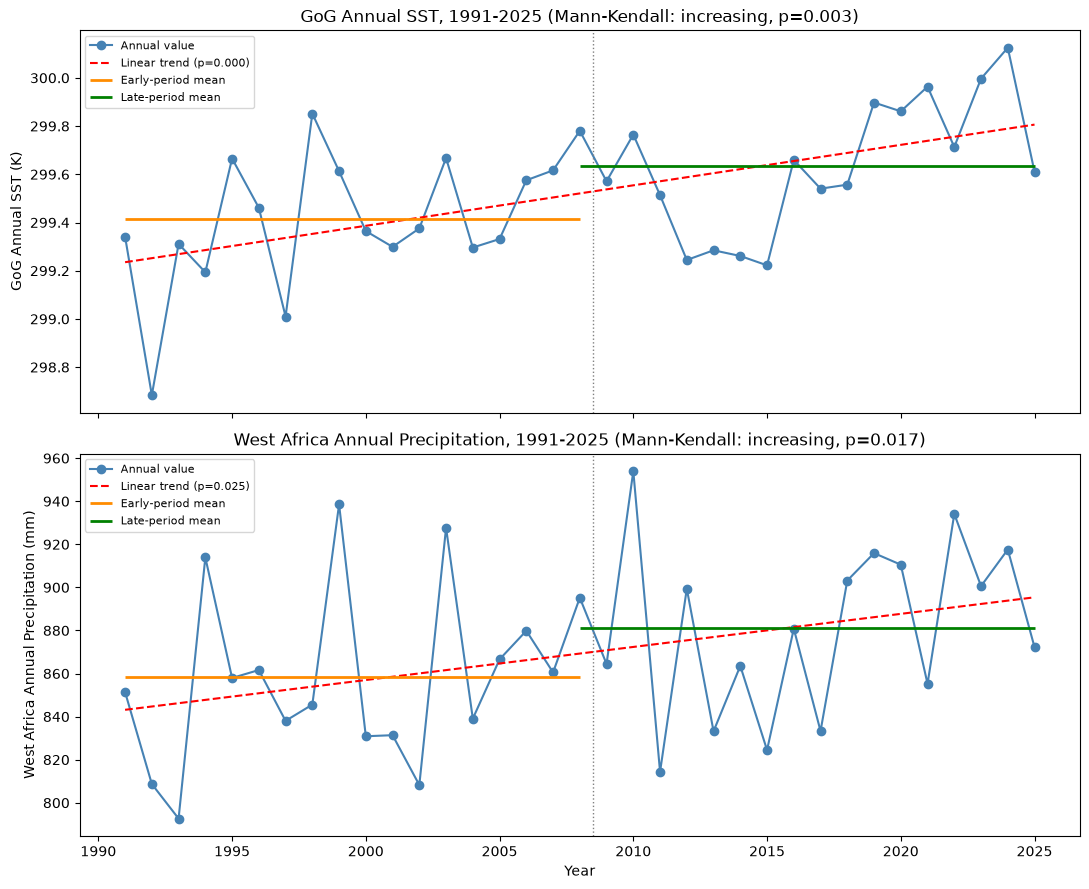

In [1]:
"""
Trend analysis for GoG SST and West Africa precipitation, 1991-2025.

Tests whether either series shows a systematic long-term trend, using
three complementary methods:
  1. Ordinary least-squares linear trend (slope, p-value)
  2. Mann-Kendall non-parametric trend test (robust to non-normality and
     outliers - the standard trend test in hydro-climatology; Mann, 1945;
     Kendall, 1975)
  3. Sen's slope estimator (median of all pairwise slopes - a robust
     trend magnitude that isn't pulled around by one or two extreme
     years; Sen, 1968)
"""

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt

SST_FILE = "SST.nc"
CRU_FILE = "cru_precip_1991_2025_westafrica.nc"
WA_LAT = (4.0, 20.0)
WA_LON = (-17.75, 15.75)
START_YEAR, END_YEAR = 1991, 2025


# Build annual SST and precipitation series

sst = xr.open_dataset(SST_FILE).rename({"valid_time": "time"})["sst"]
w_sst = np.cos(np.deg2rad(sst.latitude))
sst_monthly = sst.weighted(w_sst).mean(dim=("latitude", "longitude"), skipna=True).to_pandas()
sst_monthly.index = sst_monthly.index.to_period("M").to_timestamp()
sst_annual = sst_monthly.resample("YS").mean()
sst_annual.index = sst_annual.index.year

pre = xr.open_dataset(CRU_FILE)["pre"].sel(lat=slice(*WA_LAT), lon=slice(*WA_LON))
w_pre = np.cos(np.deg2rad(pre.lat))
pre_monthly = pre.weighted(w_pre).mean(dim=("lat", "lon"), skipna=True).to_pandas()
pre_monthly.index = pre_monthly.index.to_period("M").to_timestamp()
pre_annual = pre_monthly.resample("YS").sum()
pre_annual.index = pre_annual.index.year

sst_annual = sst_annual.loc[START_YEAR:END_YEAR]
pre_annual = pre_annual.loc[START_YEAR:END_YEAR]


# Mann-Kendall trend test + Sen's slope 
def mann_kendall(x):
    """Returns (S, Z, p_value, trend) for the Mann-Kendall test."""
    n = len(x)
    s = 0
    for i in range(n - 1):
        for j in range(i + 1, n):
            s += np.sign(x[j] - x[i])

    # variance (assumes no tied values; fine for continuous climate data)
    var_s = n * (n - 1) * (2 * n + 5) / 18

    if s > 0:
        z = (s - 1) / np.sqrt(var_s)
    elif s < 0:
        z = (s + 1) / np.sqrt(var_s)
    else:
        z = 0

    p = 2 * (1 - stats.norm.cdf(abs(z)))
    trend = "increasing" if (z > 0 and p < 0.05) else "decreasing" if (z < 0 and p < 0.05) else "no significant trend"
    return s, z, p, trend

def sens_slope(years, values):
    """Median of all pairwise slopes -- robust trend magnitude estimate."""
    n = len(years)
    slopes = []
    for i in range(n - 1):
        for j in range(i + 1, n):
            if years[j] != years[i]:
                slopes.append((values[j] - values[i]) / (years[j] - years[i]))
    return np.median(slopes)

def analyze_series(name, years, values, units):
    print(f"\n{'='*60}\n{name}\n{'='*60}")

    # 1. OLS linear trend
    lin = stats.linregress(years, values)
    print(f"Linear trend: slope={lin.slope:.5f} {units}/year, "
          f"p={lin.pvalue:.4f}, R2={lin.rvalue**2:.3f}")

    # 2. Mann-Kendall
    s, z, p_mk, trend = mann_kendall(np.asarray(values))
    print(f"Mann-Kendall: S={s}, Z={z:.3f}, p={p_mk:.4f} -> {trend}")

    # 3. Sen's slope
    slope_sen = sens_slope(np.asarray(years), np.asarray(values))
    print(f"Sen's slope: {slope_sen:.5f} {units}/year "
          f"(over {years[-1]-years[0]} years: {slope_sen*(years[-1]-years[0]):.3f} {units} total change)")

    # 4. Early vs late period t-test (split at the midpoint)
    mid = years[0] + (years[-1] - years[0]) // 2
    early = np.asarray(values)[np.asarray(years) <= mid]
    late = np.asarray(values)[np.asarray(years) > mid]
    t, p_t = stats.ttest_ind(late, early, equal_var=False)
    print(f"Early period ({years[0]}-{mid}, n={len(early)}): mean={early.mean():.3f}")
    print(f"Late period ({mid+1}-{years[-1]}, n={len(late)}): mean={late.mean():.3f}")
    print(f"Early-vs-late t-test: t={t:.3f}, p={p_t:.4f}")

    return {
        "name": name, "lin_slope": lin.slope, "lin_pvalue": lin.pvalue, "lin_r2": lin.rvalue**2,
        "mk_S": s, "mk_Z": z, "mk_pvalue": p_mk, "mk_trend": trend, "sens_slope": slope_sen,
        "early_mean": early.mean(), "late_mean": late.mean(),
        "early_late_tstat": t, "early_late_pvalue": p_t,
    }

sst_results = analyze_series("GoG Annual SST", sst_annual.index.values, sst_annual.values, "K")
pre_results = analyze_series("West Africa Annual Precipitation", pre_annual.index.values, pre_annual.values, "mm")

pd.DataFrame([sst_results, pre_results]).to_csv("trend_analysis_results.csv", index=False)
print("\nSaved: trend_analysis_results.csv")


# Plots - annual series with OLS trend line, early/late means marked

fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

for ax, (series, res, label, units) in zip(
    axes,
    [(sst_annual, sst_results, "GoG Annual SST", "K"),
     (pre_annual, pre_results, "West Africa Annual Precipitation", "mm")]
):
    years = series.index.values
    ax.plot(years, series.values, "o-", color="steelblue", label="Annual value")
    lin = stats.linregress(years, series.values)
    ax.plot(years, lin.intercept + lin.slope * years, "r--",
             label=f"Linear trend (p={lin.pvalue:.3f})")
    mid = years[0] + (years[-1] - years[0]) // 2
    ax.axvline(mid + 0.5, color="gray", linestyle=":", linewidth=1)
    ax.hlines(res["early_mean"], years[0], mid, colors="darkorange", linewidth=2, label="Early-period mean")
    ax.hlines(res["late_mean"], mid, years[-1], colors="green", linewidth=2, label="Late-period mean")
    ax.set_ylabel(f"{label} ({units})")
    ax.set_title(f"{label}, 1991-2025 (Mann-Kendall: {res['mk_trend']}, p={res['mk_pvalue']:.3f})")
    ax.legend(fontsize=8)

axes[1].set_xlabel("Year")
plt.tight_layout()
plt.savefig("trend_analysis.png", dpi=200)
print("Saved: trend_analysis.png")

Nino 3.4 series: 1991-01-01 to 2025-12-01, n=420

--- Contemporaneous correlation with Nino 3.4 ---
Nino 3.4 vs GoG SST anomaly:   R=0.018, p=0.7067
Nino 3.4 vs WA precip anomaly: R=-0.078, p=0.1107

--- Nino 3.4 -> WA precipitation anomaly, lag scan ---
 lag_months         R  p_value   n
         -3 -0.096833 0.048143 417
         -2 -0.091774 0.060840 418
         -1 -0.079968 0.102125 419
          0 -0.077947 0.110691 420
          1 -0.094369 0.053578 419
          2 -0.087702 0.073267 418
          3 -0.058717 0.231516 417
          4 -0.022902 0.641384 416
          5 -0.015848 0.747528 415
          6 -0.000416 0.993264 414
          7  0.013342 0.786899 413
          8  0.021664 0.661062 412
          9  0.037004 0.454359 411
         10  0.039335 0.426988 410
         11  0.040235 0.417055 409
         12  0.024494 0.621793 408

--- ENSO phase: dry years vs wet years (JJA mean Nino 3.4) ---
Dry years mean Nino 3.4: 0.227 (n=7)
Wet years mean Nino 3.4: -0.340 (n=8)
t-test: t=-

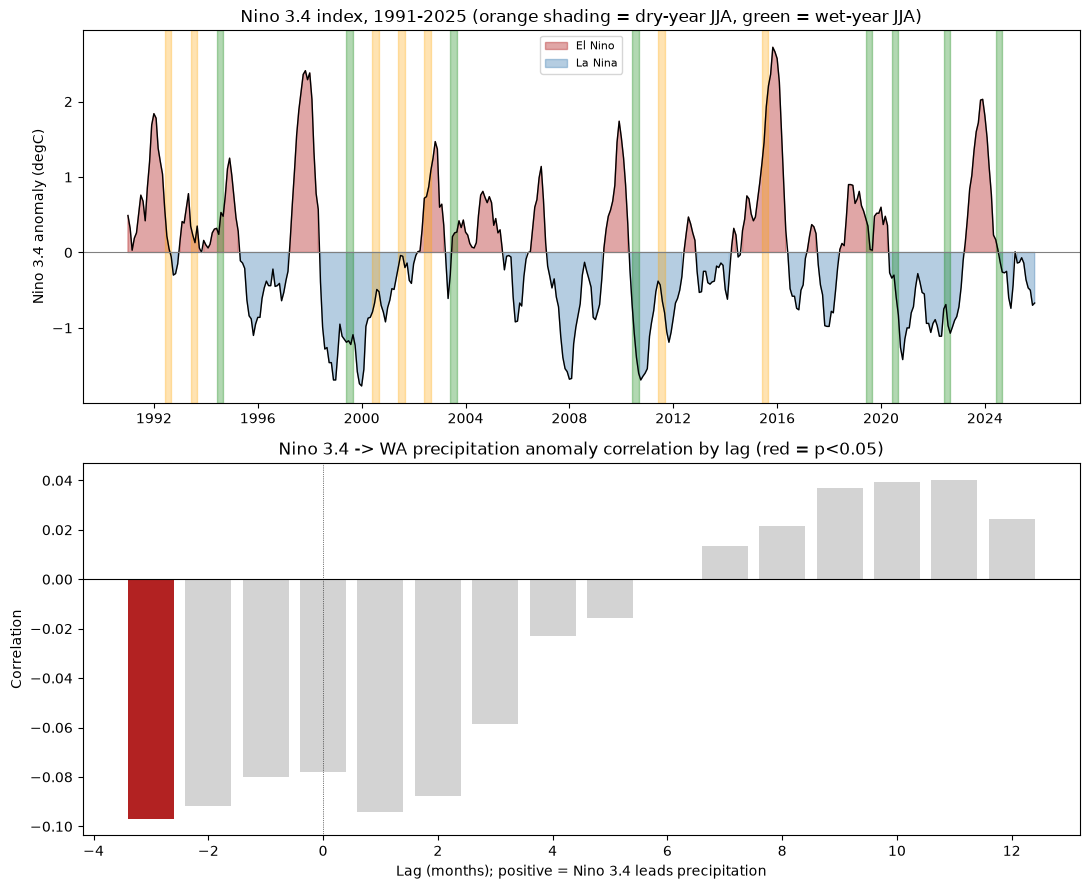

In [1]:
"""
Checks whether ENSO (El Nino-Southern Oscillation) explains the weak,
lag-independent SST-precipitation correlation found earlier, and whether
the dry/wet year classification happens to track ENSO phase.

Uses the Nino 3.4 index (monthly SST anomaly in 5N-5S, 170-120W), the
standard ENSO monitoring index, downloaded directly from NOAA/CPC
(ersst5.nino.mth.91-20.ascii -- ERSSTv5, 1991-2020 base period).

Three checks:
  1. Contemporaneous correlation: GoG SST anomaly & WA precip anomaly,
     each vs. Nino 3.4
  2. Lag scan: Nino 3.4 vs. WA precipitation anomaly, lags -3 to +12
     months (ENSO teleconnections to tropical rainfall are often lagged)
  3. Composite check: is mean Nino 3.4 during the robust dry years
     significantly different from the robust wet years? (JJA average,
     per year, two-sample t-test)
"""

import os
import urllib.request
import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt

SST_FILE = "SST.nc"
CRU_FILE = "cru_precip_1991_2025_westafrica.nc"
WA_LAT = (4.0, 20.0)
WA_LON = (-17.75, 15.75)
START_YEAR, END_YEAR = 1991, 2025

DRY_YEARS = [1992, 1993, 2000, 2001, 2002, 2011, 2015]
WET_YEARS = [1994, 1999, 2003, 2010, 2019, 2020, 2022, 2024]


# Download and parse the Nino 3.4 index

NINO_PATH = "ersst5.nino.mth.91-20.ascii"
NINO_URL = "https://www.cpc.ncep.noaa.gov/data/indices/ersst5.nino.mth.91-20.ascii"

if not os.path.exists(NINO_PATH):
    print("Downloading Nino 3.4 index (one-time)...")
    urllib.request.urlretrieve(NINO_URL, NINO_PATH)

nino_raw = pd.read_csv(NINO_PATH, sep=r"\s+", skiprows=1,
                        names=["YR", "MON", "NINO12", "NINO12_ANOM", "NINO3", "NINO3_ANOM",
                               "NINO4", "NINO4_ANOM", "NINO34", "NINO34_ANOM"])
nino_raw["date"] = pd.to_datetime(dict(year=nino_raw.YR, month=nino_raw.MON, day=1))
nino = nino_raw.set_index("date")["NINO34_ANOM"]
nino = nino.loc[f"{START_YEAR}-01":f"{END_YEAR}-12"]
print(f"Nino 3.4 series: {nino.index.min().date()} to {nino.index.max().date()}, n={len(nino)}")


# Rebuild the SST and precipitation anomaly series (same as before)

sst = xr.open_dataset(SST_FILE).rename({"valid_time": "time"})["sst"]
w_sst = np.cos(np.deg2rad(sst.latitude))
sst_m = sst.weighted(w_sst).mean(dim=("latitude", "longitude"), skipna=True).to_pandas()
sst_m.index = sst_m.index.to_period("M").to_timestamp()

pre = xr.open_dataset(CRU_FILE)["pre"].sel(lat=slice(*WA_LAT), lon=slice(*WA_LON))
w_pre = np.cos(np.deg2rad(pre.lat))
pre_m = pre.weighted(w_pre).mean(dim=("lat", "lon"), skipna=True).to_pandas()
pre_m.index = pre_m.index.to_period("M").to_timestamp()

df = pd.DataFrame({"SST": sst_m, "PRE": pre_m, "NINO34": nino}).dropna()
df["month"] = df.index.month
df["SST_anom"] = df["SST"] - df.groupby("month")["SST"].transform("mean")
df["PRE_anom"] = df["PRE"] - df.groupby("month")["PRE"].transform("mean")


# Contemporaneous correlations with Nino 3.4

print("\n--- Contemporaneous correlation with Nino 3.4 ---")
r_sst, p_sst = stats.pearsonr(df["NINO34"], df["SST_anom"])
print(f"Nino 3.4 vs GoG SST anomaly:   R={r_sst:.3f}, p={p_sst:.4f}")
r_pre, p_pre = stats.pearsonr(df["NINO34"], df["PRE_anom"])
print(f"Nino 3.4 vs WA precip anomaly: R={r_pre:.3f}, p={p_pre:.4f}")


# Lag scan: Nino 3.4 (t) vs WA precipitation anomaly (t+lag)

print("\n--- Nino 3.4 -> WA precipitation anomaly, lag scan ---")
lag_results = []
for lag in range(-3, 13):
    shifted = df["PRE_anom"].shift(-lag)
    valid = pd.DataFrame({"x": df["NINO34"], "y": shifted}).dropna()
    r, p = stats.pearsonr(valid["x"], valid["y"])
    lag_results.append({"lag_months": lag, "R": r, "p_value": p, "n": len(valid)})
lag_df = pd.DataFrame(lag_results)
print(lag_df.to_string(index=False))
lag_df.to_csv("enso_lag_scan.csv", index=False)


# Does ENSO phase differ between the robust dry and wet year groups?

jja = df[df["month"].isin([6, 7, 8])]
nino_jja_annual = jja.groupby(jja.index.year)["NINO34"].mean()

dry_nino = nino_jja_annual.loc[DRY_YEARS]
wet_nino = nino_jja_annual.loc[WET_YEARS]
t, p = stats.ttest_ind(wet_nino, dry_nino, equal_var=False)

print("\n--- ENSO phase: dry years vs wet years (JJA mean Nino 3.4) ---")
print(f"Dry years mean Nino 3.4: {dry_nino.mean():.3f} (n={len(dry_nino)})")
print(f"Wet years mean Nino 3.4: {wet_nino.mean():.3f} (n={len(wet_nino)})")
print(f"t-test: t={t:.3f}, p={p:.4f}")

by_group = pd.concat([
    dry_nino.to_frame("Nino34_JJA").assign(group="dry"),
    wet_nino.to_frame("Nino34_JJA").assign(group="wet"),
])
print(by_group)
by_group.to_csv("enso_by_group.csv")


# Plot

fig, axes = plt.subplots(2, 1, figsize=(11, 9))

axes[0].plot(df.index, df["NINO34"], color="black", linewidth=1)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].fill_between(df.index, 0, df["NINO34"], where=df["NINO34"] > 0,
                      color="firebrick", alpha=0.4, label="El Nino")
axes[0].fill_between(df.index, 0, df["NINO34"], where=df["NINO34"] < 0,
                      color="steelblue", alpha=0.4, label="La Nina")
for y in DRY_YEARS:
    axes[0].axvspan(pd.Timestamp(f"{y}-06-01"), pd.Timestamp(f"{y}-09-01"), color="orange", alpha=0.3)
for y in WET_YEARS:
    axes[0].axvspan(pd.Timestamp(f"{y}-06-01"), pd.Timestamp(f"{y}-09-01"), color="green", alpha=0.3)
axes[0].set_title("Nino 3.4 index, 1991-2025 (orange shading = dry-year JJA, green = wet-year JJA)")
axes[0].set_ylabel("Nino 3.4 anomaly (degC)")
axes[0].legend(fontsize=8)

colors = ["firebrick" if p < 0.05 else "lightgray" for p in lag_df.p_value]
axes[1].bar(lag_df.lag_months, lag_df.R, color=colors)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].axvline(0, color="black", linewidth=0.5, linestyle=":")
axes[1].set_xlabel("Lag (months); positive = Nino 3.4 leads precipitation")
axes[1].set_ylabel("Correlation")
axes[1].set_title("Nino 3.4 -> WA precipitation anomaly correlation by lag (red = p<0.05)")

plt.tight_layout()
plt.savefig("enso_check.png", dpi=200)
print("\nSaved: enso_lag_scan.csv, enso_by_group.csv, enso_check.png")

C:\Users\HP\AppData\Local\Temp\ipykernel_16832\3103432556.py:73: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  return stats.ttest_ind(sample_wet, sample_dry, axis=0, equal_var=False, nan_policy="omit")
C:\Users\HP\AppData\Local\Temp\ipykernel_16832\3103432556.py:73: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  return stats.ttest_ind(sample_wet, sample_dry, axis=0, equal_var=False, nan_policy="omit")


Variable  Season    Sig cells   Total valid   % significant
SST       Annual    7832        8705          90.0%
MSLP      Annual    0           20413         0.0%
Q         Annual    7254        20413         35.5%
SST       JJA       2991        8705          34.4%
MSLP      JJA       2388        20413         11.7%
Q         JJA       5083        20413         24.9%

Saved: significance_annual_jja_summary.csv
Saved: Figure6_annual_and_JJA_significance.png


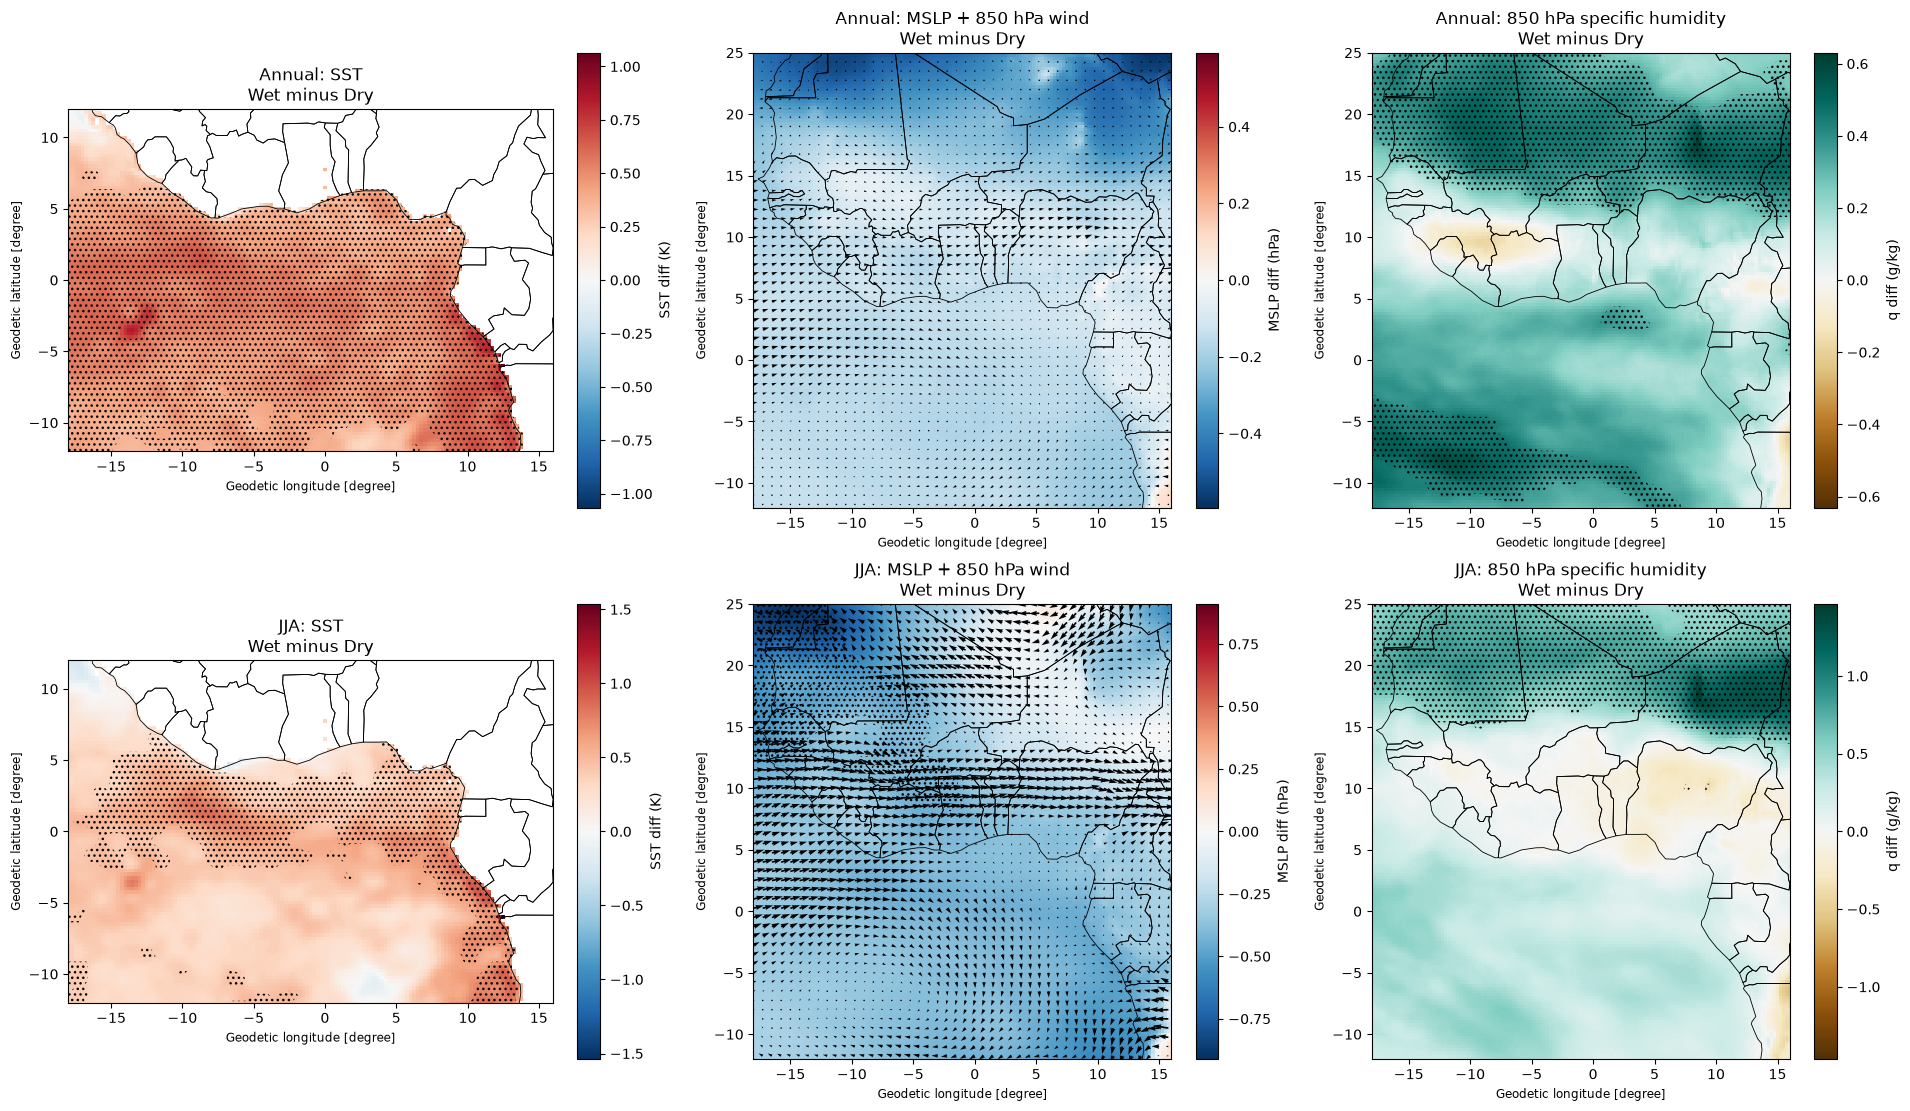

In [1]:
"""
Statistical significance testing on wet-minus-dry composite differences,
computed TWICE and independently: once for the Annual mean, once for the
JJA (June-August) season. These are complementary results, not a
comparison to determine which season is "better" - the Annual test shows
the overall-year difference and its significance, the JJA test shows the
peak-monsoon-season difference and its significance.

For each grid cell, a Welch's two-sample t-test (unequal variance, n_dry=7
vs n_wet=8) compares the 7 dry-year means against the 8 wet-year means,
separately for the Annual and JJA aggregations. Grid cells where p < 0.05
are hatched on the difference maps.
"""

import os
import urllib.request
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats
import geopandas as gpd

DRY_YEARS = [1992, 1993, 2000, 2001, 2002, 2011, 2015]
WET_YEARS = [1994, 1999, 2003, 2010, 2019, 2020, 2022, 2024]
ALPHA = 0.05


# Country boundaries (reused from earlier figures)

GEOJSON_PATH = "countries.geojson"
GEOJSON_URL = ("https://raw.githubusercontent.com/nvkelso/"
               "natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson")
if not os.path.exists(GEOJSON_PATH):
    urllib.request.urlretrieve(GEOJSON_URL, GEOJSON_PATH)
world = gpd.read_file(GEOJSON_PATH)

def add_boundaries(ax, extent):
    world.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")

# Load data

sst = xr.open_dataset("SST.nc").rename({"valid_time": "time"})["sst"]
mslp = xr.open_dataset("MSLP.nc").rename({"valid_time": "time"})["msl"] / 100.0
wsh = xr.open_dataset("Wind_SH.nc").rename({"valid_time": "time"}).squeeze("pressure_level", drop=True)
u = wsh["u"]
v = wsh["v"]
q = wsh["q"] * 1000.0

SST_EXTENT = [float(sst.longitude.min()), float(sst.longitude.max()),
              float(sst.latitude.min()), float(sst.latitude.max())]
WA_EXTENT = [float(mslp.longitude.min()), float(mslp.longitude.max()),
             float(mslp.latitude.min()), float(mslp.latitude.max())]


# Per-year samples, for a given month list (None = all 12 = Annual)

def per_year_samples(da, years, months=None):
    d = da if months is None else da.sel(time=da["time"].dt.month.isin(months))
    yearly = d.groupby("time.year").mean("time")
    return yearly.sel(year=years)

def welch_ttest_grid(sample_dry, sample_wet):
    return stats.ttest_ind(sample_wet, sample_dry, axis=0, equal_var=False, nan_policy="omit")

def compute_block(da, months):
    dry = per_year_samples(da, DRY_YEARS, months)
    wet = per_year_samples(da, WET_YEARS, months)
    diff = wet.mean("year") - dry.mean("year")
    _, p = welch_ttest_grid(dry.values, wet.values)
    return diff, p

SEASONS = {"Annual": None, "JJA": [6, 7, 8]}
results = {}

for sname, months in SEASONS.items():
    results[sname] = {}
    results[sname]["SST"] = compute_block(sst, months)
    results[sname]["MSLP"] = compute_block(mslp, months)
    results[sname]["U"] = compute_block(u, months)
    results[sname]["V"] = compute_block(v, months)
    results[sname]["Q"] = compute_block(q, months)

# 3. Report percentage of grid cells significant, both seasons

print(f"{'Variable':<10}{'Season':<10}{'Sig cells':<12}{'Total valid':<14}{'% significant'}")
summary_rows = []
for sname in SEASONS:
    for vname in ["SST", "MSLP", "Q"]:
        _, p = results[sname][vname]
        valid = ~np.isnan(p)
        n_valid = int(valid.sum())
        n_sig = int(np.sum(p[valid] < ALPHA))
        pct = 100 * n_sig / n_valid
        print(f"{vname:<10}{sname:<10}{n_sig:<12}{n_valid:<14}{pct:.1f}%")
        summary_rows.append((vname, sname, n_sig, n_valid, pct))

import csv
with open("significance_annual_jja_summary.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["variable", "season", "significant_cells", "total_valid_cells", "pct_significant"])
    writer.writerows(summary_rows)
print("\nSaved: significance_annual_jja_summary.csv")


# 4. Plot: 2 rows (Annual, JJA) x 3 columns (SST, MSLP+wind, humidity)

fig, axes = plt.subplots(2, 3, figsize=(19, 11), constrained_layout=True)

col_titles = ["SST", "MSLP + 850 hPa wind", "850 hPa specific humidity"]
for col, title in enumerate(col_titles):
    axes[0, col].set_title(f"Annual: {title}\nWet minus Dry")
    axes[1, col].set_title(f"JJA: {title}\nWet minus Dry")

for row, sname in enumerate(["Annual", "JJA"]):
    diff, p = results[sname]["SST"]
    ax = axes[row, 0]
    vmax = np.nanmax(np.abs(diff.values))
    im = ax.pcolormesh(diff.longitude, diff.latitude, diff.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    plt.colorbar(im, ax=ax, label="SST diff (K)")
    sig_mask = (p < ALPHA).astype(float)
    ax.contourf(diff.longitude, diff.latitude, sig_mask, levels=[0.5, 1.5], colors="none", hatches=["..."])
    add_boundaries(ax, SST_EXTENT)

    diff_m, p_m = results[sname]["MSLP"]
    diff_u, _ = results[sname]["U"]
    diff_v, _ = results[sname]["V"]
    ax = axes[row, 1]
    vmax = np.nanmax(np.abs(diff_m.values))
    im = ax.pcolormesh(diff_m.longitude, diff_m.latitude, diff_m.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    plt.colorbar(im, ax=ax, label="MSLP diff (hPa)")
    sig_mask = (p_m < ALPHA).astype(float)
    ax.contourf(diff_m.longitude, diff_m.latitude, sig_mask, levels=[0.5, 1.5], colors="none", hatches=["..."])
    skip = 3
    ax.quiver(diff_u.longitude[::skip], diff_u.latitude[::skip],
              diff_u.values[::skip, ::skip], diff_v.values[::skip, ::skip], scale=40, width=0.004)
    add_boundaries(ax, WA_EXTENT)

    diff_q, p_q = results[sname]["Q"]
    ax = axes[row, 2]
    vmax = np.nanmax(np.abs(diff_q.values))
    im = ax.pcolormesh(diff_q.longitude, diff_q.latitude, diff_q.values, cmap="BrBG", vmin=-vmax, vmax=vmax)
    plt.colorbar(im, ax=ax, label="q diff (g/kg)")
    sig_mask = (p_q < ALPHA).astype(float)
    ax.contourf(diff_q.longitude, diff_q.latitude, sig_mask, levels=[0.5, 1.5], colors="none", hatches=["..."])
    add_boundaries(ax, WA_EXTENT)

plt.savefig("Figure6_annual_and_JJA_significance.png", dpi=200)
print("Saved: Figure6_annual_and_JJA_significance.png")